PYTHON PROJECT TP53 Fasta file

TASK 1: FASTA ANALYSIS



In [25]:


with open( "tp53_sequences.fasta", "r") as f:
    header = f.readline().strip()

print(header)
header = header[1:]
seq_id = header.split()[0]

print("Sequence ID:", seq_id)
print("Full description:", header)


>NC_000017.11:c7687490-7668421 TP53 [organism=Homo sapiens] [GeneID=7157] [chromosome=17]
Sequence ID: NC_000017.11:c7687490-7668421
Full description: NC_000017.11:c7687490-7668421 TP53 [organism=Homo sapiens] [GeneID=7157] [chromosome=17]


The output is sequence ID which was calculated using fasta header.

In [9]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 12.0 MB/s eta 0:00:00


SEQUENCE ID

In [15]:
from Bio import SeqIO

record = next(SeqIO.parse("tp53_sequences.fasta", "fasta"))
print(record.id)


NC_000017.11:c7687490-7668421


Calculate using Biopython

In [57]:
from Bio import SeqIO


for record in SeqIO.parse("tp53_sequences.fasta", "fasta"):
    seq = str(record.seq).upper()
    # sequence id:
    seq_id = record.id
   #sequence length:
    length = len(seq)

    #Nucleotide composition:
    a = seq.count("A")
    t = seq.count("T")
    g = seq.count("G")
    c = seq.count("C")
    #GC and AT percentage calculation:
    gc = (g + c) / length * 100
    at = (a + t) / length * 100

    print("ID:", seq_id)
    print("Length:", length)
    print("A:", a, "T:", t, "G:", g, "C:", c)
    print("GC%:", round(gc, 2))
    print("AT%:", round(at, 2))
    print("-" * 40)

ID: NC_000017.11:c7687490-7668421
Length: 19070
A: 4966 T: 4688 G: 4778 C: 4638
GC%: 49.38
AT%: 50.62
----------------------------------------
ID: NC_060941.1:c7591594-7572544
Length: 19051
A: 4959 T: 4686 G: 4772 C: 4634
GC%: 49.37
AT%: 50.63
----------------------------------------


NC_000017:
The first calculation which has analyzed sequences and lenght of 19070 sequences which is composed of nucleotides
A: 4966 T: 4688 G:4778 C: 4638
GC% represents proportion of G andC in sequences = 49.38%
AT% represents proportion of A and T in sequences = 50.62%
 NC_06094:
 The second calculation which has analyzed sequences and lenght of  sequences 19051 which is composed of nucleotides
A: 4959 T: 4686 G:4772 C: 4634
GC% represents proportion of G andC in sequences = 49.37%
AT% represents proportion of A and T in sequences = 50.63%

The above output was calculated using biopython were


In [73]:
#VALIDATION
from Bio import SeqIO

valid_bases = set("ATGC")

for record in SeqIO.parse("tp53_sequences.fasta", "fasta"):
    sequence = str(record.seq).upper()
    seq_id = record.id

    if set(sequence).issubset(valid_bases):
        print(f"{seq_id} is valid")
    else:
        print(seq_id, "contains invalid characters")

NC_000017.11:c7687490-7668421 is valid
NC_060941.1:c7591594-7572544 is valid


Gene-Expression data using pandas

Step:1 Import libraries

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

Step:2 load CSV file

In [72]:
df= pd.read_csv("expmatrix.csv")
df= pd.read_csv("metadata.csv")

Step:3 INSPECTION OF DATA





In [88]:
expression = pd.read_csv("expmatrix.csv")
metadata = pd.read_csv("metadata.csv")

print("Metadata shape:", metadata.shape)
print("Expression matrix shape:", expression.shape)

Metadata shape: (121, 3)
Expression matrix shape: (21755, 122)


The above output was calculated gives us idea about number of rows and columns present in the CSV files
Metadata.csv (Rows=121,Columns=3)
Expmatric.csv(Rows=21755,Columns=122)

In [102]:
print("EXPRESSION MATRIX")
df= pd.read_csv ("expmatrix.csv")
print(df.shape)
print(df.columns)
display(df.head())
df.info()


EXPRESSION MATRIX
(21755, 122)
Index(['Gene_Symbol', 'GSM1045191', 'GSM1045192', 'GSM1045193', 'GSM1045194',
       'GSM1045195', 'GSM1045196', 'GSM1045197', 'GSM1045198', 'GSM1045199',
       ...
       'GSM1045302', 'GSM1045303', 'GSM1045304', 'GSM1045305', 'GSM1045306',
       'GSM1045307', 'GSM1045308', 'GSM1045309', 'GSM1045310', 'GSM1045311'],
      dtype='object', length=122)


,Gene_Symbol,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
0,A1BG,3.403199,4.037233,3.860598,3.937074,3.937074,3.703477,4.107623,4.037233,3.481865,...,4.037233,3.224321,6.416550,7.209327,3.937074,4.244924,4.037233,4.037233,4.037233,4.392838
1,A1BG-AS1,4.045971,4.219688,4.280795,4.066748,4.066748,4.066748,4.045971,4.066748,4.219688,...,4.926807,4.840869,5.821870,4.445857,4.280795,4.406667,4.280795,4.418040,4.201013,4.280795
2,A1CF,2.319143,2.320107,3.449948,2.376034,2.320107,2.320107,2.320107,2.320107,2.363784,...,2.660781,2.399112,2.320107,2.503999,2.653309,2.342085,2.320107,2.630298,2.342954,2.320107
3,A2M,6.435412,6.423260,3.687021,6.384210,6.557870,6.203332,6.275541,6.555386,5.938598,...,4.412873,6.359712,6.171743,5.104726,5.263980,6.590134,5.938452,5.853099,6.099390,6.294528
4,A2M-AS1,4.355747,3.154174,2.751123,2.775390,4.385987,4.386269,4.020623,4.309158,4.216733,...,2.971182,2.887447,3.055569,2.750754,2.666184,3.402097,2.775390,2.312812,2.507649,3.087933


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21755 entries, 0 to 21754
Columns: 122 entries, Gene_Symbol to GSM1045311
dtypes: float64(121), object(1)
memory usage: 20.2+ MB


The above output gives
 expmatrix.csv file (df) shape and displays the head of the data which are top 5 rows of the data so we can check what is present in the df.

In [85]:
print("SAMPLE METADATA")
print(metadata.shape)
print(metadata.columns)
display(metadata.head())
metadata.info()

SAMPLE METADATA
(121, 3)
Index(['Sample', 'Sample_Title', 'Condition'], dtype='object')


,Sample,Sample_Title,Condition
0,GSM1045191,"Normal breast, N1_15_12_04",Normal
1,GSM1045192,"Normal breast, N4_14_12_04",Normal
2,GSM1045193,"Normal breast, N5_15_12_04",Normal
3,GSM1045194,"Normal breast, N6_14_12_04",Normal
4,GSM1045195,"Normal breast, P1_15_12_04",Normal


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Sample        121 non-null    object
 1   Sample_Title  121 non-null    object
 2   Condition     121 non-null    object
dtypes: object(3)
memory usage: 3.0+ KB


The above output gives
 metadata.csv file (df) shape and displays the head of the data which are top 4 rows of the data so we can check what is present in the df.

Step 4: Check data quality

In [129]:
print("SAMPLE EXPRESSION")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

SAMPLE EXPRESSION
Gene_Symbol    0
GSM1045191     0
GSM1045192     0
GSM1045193     0
GSM1045194     0
              ..
GSM1045307     0
GSM1045308     0
GSM1045309     0
GSM1045310     0
GSM1045311     0
Length: 122, dtype: int64
Duplicate rows: 0


The above output is data checking which gives us idea about duplicated rows if present in the (df) as duplicate values can disorient the results The expmatrix doesn't contain any duplicates(0)

In [130]:
print("SAMPLE METADATA")
print(metadata.isna().sum())
print("Duplicate rows:", metadata.duplicated().sum())

SAMPLE METADATA
Sample          0
Sample_Title    0
Condition       0
dtype: int64
Duplicate rows: 0


The above output is data checking which gives us idea about duplicated rows if present in the (df) as duplicate values can disorient the results The metadata doesn't contain any duplicates(0).

Step 5: Exploring the measurments

In [140]:
import pandas as pd
# Loading of iles
expr = pd.read_csv("expmatrix.csv")
meta = pd.read_csv("metadata.csv")

# 1.Selected genes which are closely related to breast cancer
genes = ["TP53", "BRCA1", "ERBB2", "ESR1", "MKI67"]
data = expr[expr["Gene_Symbol"].isin(genes)].set_index("Gene_Symbol")

# 2. splitting of samples into Cancer and Normal
cancer_ids = meta[meta["Condition"] == "Cancer"]["Sample"]
normal_ids = meta[meta["Condition"] == "Normal"]["Sample"]
cancer = data[cancer_ids]
normal = data[normal_ids]
print(cancer.shape)
print(normal.shape)

# 3. mean and median for each gene
print("Cancer mean:")
print(cancer.mean(axis=1).round(2))
print("Normal mean:")
print(normal.mean(axis=1).round(2))
print("Cancer median:")
print(cancer.median(axis=1).round(2))
print("Normal median:")
print(normal.median(axis=1).round(2))

# 4. check missing values (Nan)
print("Missing values:", expr.isna().sum().sum())

# 5. summary of all measurements
print(expr.drop(columns="Gene_Symbol").stack().describe().round(2))

(5, 104)
(5, 17)
Cancer mean:
Gene_Symbol
BRCA1    4.14
ERBB2    4.33
ESR1     3.52
MKI67    4.59
TP53     3.08
dtype: float64
Normal mean:
Gene_Symbol
BRCA1    3.96
ERBB2    3.10
ESR1     3.17
MKI67    3.61
TP53     2.73
dtype: float64
Cancer median:
Gene_Symbol
BRCA1    4.06
ERBB2    4.04
ESR1     3.51
MKI67    4.46
TP53     2.97
dtype: float64
Normal median:
Gene_Symbol
BRCA1    3.96
ERBB2    2.99
ESR1     3.16
MKI67    3.36
TP53     2.70
dtype: float64
Missing values: 0
count    2632355.00
mean           4.25
std            2.15
min            2.31
25%            2.34
50%            3.58
75%            5.49
max           15.81
dtype: float64


1 Identifying the relevant genes:
The relevant genes means which related to causing of cancer and 5 genes from the (df) closely relate to causing the breast cancer
GENES:
 ["TP53", "BRCA1", "ERBB2", "ESR1", "MKI67"]
 MEAN :
 CANCER
 The mean was calculated of cancer samples the highest mean was of gene ="MKI67"
 NORMAL
 The means of normal (contol) samples was colculated  and the highest mean gene ="BRCA1"
 MEDIAN:
 CANCER
 The median was calculated of cancer samples the highest median was of gene ="MKI67"
 NORMAL
 The means of normal (contol) samples was calculated and the highest median gene ="BRCA1"
MISSING VALUES:
The (df) doesn't contain any missing values.
SUMMARY VALUES:
This gives the idea about minmum quarter and max expression values
 min = 2.31
 25% =2.34
 MEDIAN 50%= 3.58
 75% = 5.49
 MAX = 15.81

In [137]:
cancer_ids = meta[meta["Condition"] == "Cancer"]["Sample"]
normal_ids = meta[meta["Condition"] == "Normal"]["Sample"]
cancer = data[cancer_ids]
normal = data[normal_ids]
print(cancer.shape)
print(normal.shape)

(5, 104)
(5, 17)


VISUALIZATION

In [10]:
import pandas as pd
import matplotlib as plt

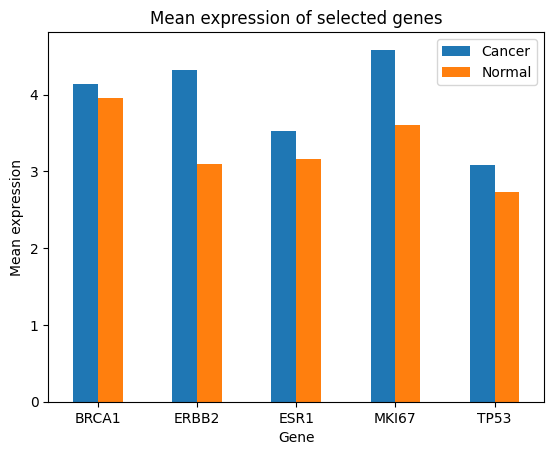

In [133]:
means.plot(kind="bar")
plt.title("Mean expression of selected genes")
plt.xlabel("Gene")
plt.ylabel("Mean expression")
plt.xticks(rotation=0)
plt.savefig("plot1_bar_chart.png")
plt.show()

The bar chart gives the average expression values in cancer and non cancer samples between 5 selected genes the highest expression mean gene= MKI67 then ERBB2 the ERBB2 gene has much difference between the cancer and normal mean . The ERBB2 gene causes gene amplification which leads to overexpression of protein and aggressive tumor growth . The MKI67 causes cell proliferation which could also divide the cancer cells .The BRCA1 have less difference between the cancer and normal as it is a tumor suppressor gene.

HISTOGRAM

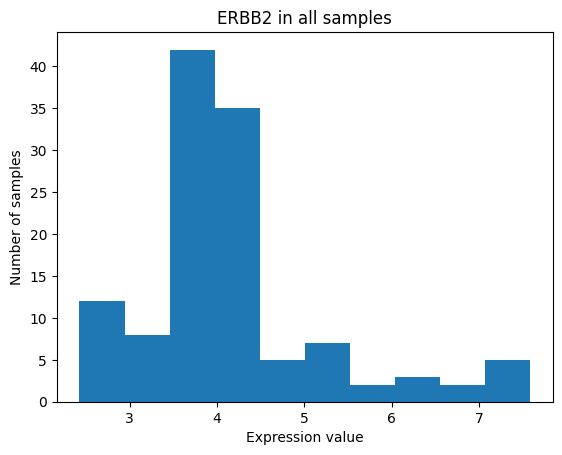

In [145]:
plt.hist(data.loc["ERBB2"])
plt.title("ERBB2 in all samples")
plt.xlabel("Expression value")
plt.ylabel("Number of samples")
plt.savefig("plot2_histogram.png")
plt.show()

The histogram illustrates the distribution of ERBB2 gene expression across all samples. Most samples show expression values between approximately 3.5 and 4.5, with the highest frequency observed around 3.5–4.0. A smaller proportion of samples exhibit higher expression values, extending beyond 5.0 and reaching approximately 7.5. This indicates variability in ERBB2 expression across the dataset. However, since normal and cancer samples are combined, this histogram alone cannot establish whether ERBB2 expression is higher in cancer samples.

BOX PLOT

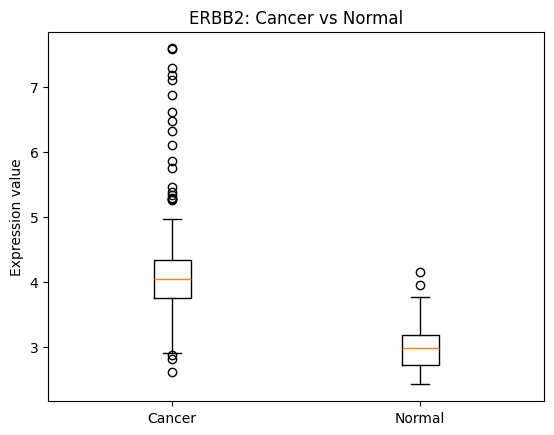

In [151]:
plt.boxplot([cancer_data.loc["ERBB2"], normal_data.loc["ERBB2"]])
plt.xticks([1, 2], ["Cancer", "Normal"])
plt.title("ERBB2: Cancer vs Normal")
plt.ylabel("Expression value")
plt.savefig("plot3_boxplot.png")
plt.show()

The box plot shows that ERBB2 expression is higher in cancer samples than in normal samples. The mean expression was 4.327 in cancer samples and 3.096 in normal samples, giving a mean difference of 1.231. The median expression was also higher in the cancer group (4.038) than in the normal group (2.988). Cancer samples exhibited greater values in expression, with several high-expression outliers. These findings suggests association between higher ERBB2 expression and cancer group in dataset.

In [162]:
import pandas as pd

# Extracting the ERBB2 series from the dataset variables
cancer_ERBB2 = cancer_data.loc["ERBB2"]
normal_ERBB2 = normal_data.loc["ERBB2"]

print("Cancer:")
print(cancer_ERBB2.describe(percentiles=[0.25, 0.50, 0.75]))

print("\nNormal:")
print(normal_ERBB2.describe(percentiles=[0.25, 0.50, 0.75]))

Cancer:
count    104.000000
mean       4.326985
std        1.028218
min        2.610126
25%        3.758587
50%        4.038201
75%        4.339088
max        7.586887
Name: ERBB2, dtype: float64

Normal:
count    17.000000
mean      3.096278
std       0.481881
min       2.424787
25%       2.724680
50%       2.988028
75%       3.185919
max       4.149272
Name: ERBB2, dtype: float64


The summary values ERBB2 between cancer and normal based on which box plot was plotted .
The reason behind choosing this gene
ERBB2 (HER2)
- Strongly associated with a specific subtype of breast cancer.
- Its expression differs substantially between the cancer and normal samples,


OBSERVATION:

Among the five selected genes, MKI67 and ERBB2 showed the highest average expression in the Cancer samples (means of 4.59 and 4.33). Both were higher in Cancer than in Normal samples (MKI67: 4.59 vs 3.61; ERBB2: 4.33 vs 3.10), and ERBB2 showed the largest difference (about 1.23, compared with 0.98 for MKI67 and 0.35 or less for the other three genes). ERBB2 (also called HER2) is associated with a specific breast cancer subtype, HER2-positive, so the higher average may be driven by a subset of samples with very high values. MKI67 encodes Ki-67, a marker of cell proliferation that is present in dividing cells and absent in resting cells. Higher expression is consistent with faster-growing tissue. However, neither gene defines or diagnoses cancer on its own, and Ki-67 values can differ between labs and observers. These are observations in this dataset only: the Normal group has just 17 samples, the groups overlap, and a difference in averages does not establish statistical significance or causation.

LIMITATION:
This analysis is limited by the small Normal group (17 vs 104 Cancer samples), overlap between the groups, and the use of only five selected genes. No statistical test was performed, the samples may differ in other unrecorded ways, and the data comes from a single study. The results show an association in this dataset and cannot prove or diagnose breast cancer. Diagnosis depends on tests such as biopsy, imaging (mammography or ultrasound), and receptor testing (ER, PR, HER2).

In [163]:
import pandas as pd

# Extracting the ERBB2 series from the dataset variables
cancer_ERBB2 = cancer_data.loc["MKI67"]
normal_ERBB2 = normal_data.loc["MKI67"]

print("Cancer:")
print(cancer_ERBB2.describe(percentiles=[0.25, 0.50, 0.75]))

print("\nNormal:")
print(normal_ERBB2.describe(percentiles=[0.25, 0.50, 0.75]))

Cancer:
count    104.000000
mean       4.586244
std        0.811540
min        3.049642
25%        3.967829
50%        4.460907
75%        4.991410
max        6.633594
Name: MKI67, dtype: float64

Normal:
count    17.000000
mean      3.609758
std       0.694698
min       3.096139
25%       3.257878
50%       3.364923
75%       3.544044
max       5.672501
Name: MKI67, dtype: float64
